In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import logging
#logging.basicConfig(level=logging.DEBUG)

from spectre import SPECTREout, SPECTRE, plot_infaces, get_xinit_specwrap, force_real

%load_ext autoreload
%autoreload 2
#%matplotlib ipympl

np.set_printoptions(linewidth=170)

[spcpc629:13536] mca_base_component_repository_open: unable to open mca_btl_openib: librdmacm.so.1: cannot open shared object file: No such file or directory (ignored)


In [ ]:
# W7-X fixed points example, based on the .h5 output file

out = SPECTREout('test_w7x.h5')

init_pts=[ np.array([[x, 0.] for x in np.linspace(-1,1, 15)]) for _ in range(7)] # starting points for poincare section
out.trace_fieldlines(init_pts, num_threads=7, num_phi_planes=1, num_transits=500) #run calculation



Magnetic axis r z s t:  5.949069118110934 1.6296334118531316e-12 -0.9495670090669367 6.2831853070973605
Island o-point r z s t:  6.038042299243705 0.609353149706724 -0.4178454143175019 5.393506909379445
Island o-point r z s t:  5.702463879183286 -1.262384590502385e-10 -0.6179206147682522 3.1415926534552265


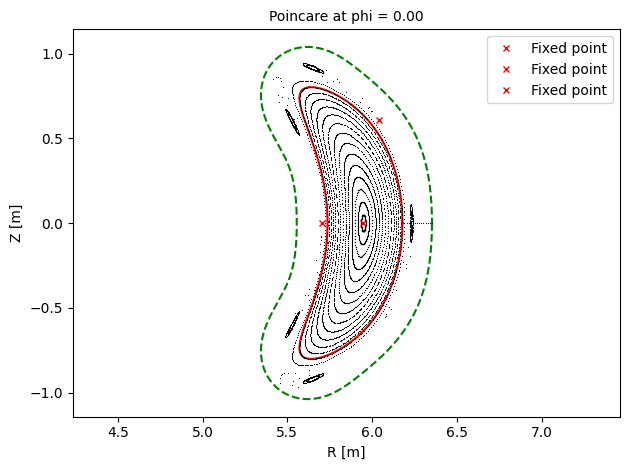

In [4]:
out.plot_infaces(ax=plt.gca())

out.tracer.plot(ax=plt.gca())

# Find the axis - works
r, z, s, t = out.find_axis(guess=[-0.989, 3.14], nrestart=100, plot=True, ax=plt.gca())
print("Magnetic axis r z s t: ", r, z, s, t)

# Find the island fixed points. First is with a bad guess, so it will retry and find a random point. 
# Due to the hyperblic nature of x-points, this is very likely an o-point.
r, z, s, t = out.find_island_fixed_point(vol=1, m=5, n=-5, guess=[0.1, 0 ], nrestart=10, plot=True, ax=plt.gca())
print("Island o-point r z s t: ", r, z, s, t)

# start with a good guess, this will converge to the inboard x-point.
r, z, s, t = out.find_island_fixed_point(vol=1, m=5, n=-5, guess=[-.5, np.pi], nrestart=0, plot=True, ax=plt.gca())
print("Island o-point r z s t: ", r, z, s, t)

plt.legend()
plt.tight_layout()



readin :            : 
readin :     255.25 : Igeometry=  3 ; enforce_stell_sym=  T ; Lreflect=  0 ; Lbdybnzero= T 
readin :            : Lfreebound=  1 ; phiedge=  1.749725650650050E+00 ; curtor=  0.000000000000000E+00 ; curpol=  1.017876019628700E+02 
readin :            : gamma=  0.000000000000000E+00 
readin :            : Nfp=  5 ; Nvol=  1 ; Mvol=  2 ; Mpol= 12 ; Ntor= 12 
readin :            : pscale=  0.00000E+00 ; Ladiabatic= 0 ; Lconstraint=  3 ; mupf: tol,its=  1.00E-16,  16 
readin :            : Lrad = 14, 8,
readin :            : 
readin :     255.25 : Linitialize=  1 ;LautoinitBn=  0 ; Lzerovac= 0 ; Ndiscrete= 2 
readin :            : Nquad=  -1 ; iMpol=  -4 ; iNtor=  -4 
readin :            : 
readin :            : 
readin :            : escale=  0.00000E+00 ; opsilon=  1.00000E+00 ; pcondense=  4.000 ; epsilon=  1.00000E+00 ; wpoloidal        = 1.0000 ; upsilon=  1.00000E+00 
readin :            : mfreeits=  12 ; gBntol=  1.00000E-05 ; gBnbld=  6.66000E-01 
readin :    

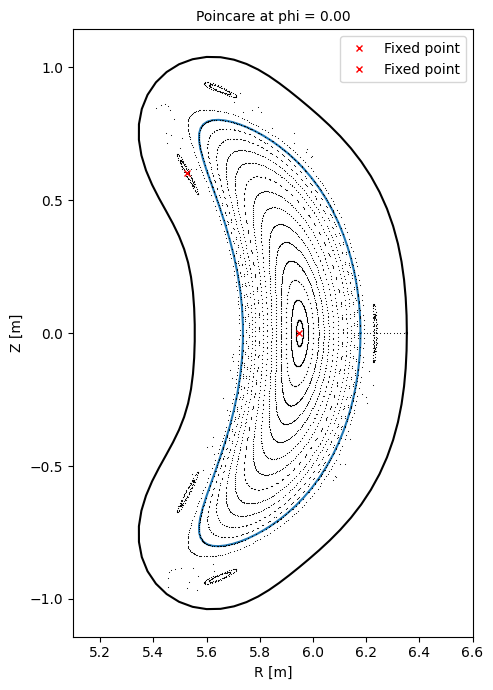

In [8]:
# W7-X fixed points example, based on the .toml input file

spectre = SPECTRE.from_input_file('test_w7x.toml')

xin = get_xinit_specwrap(spectre)  # get the interface modes for field calc and plotting

force_real(xin, spectre)  # force spectre to generate fields internally

init_pts=[ np.array([[x, 0.] for x in np.linspace(-1,1, 15)]) for _ in range(2)]
spectre.trace_fieldlines(init_pts, num_threads=7, num_phi_planes=1, num_transits=300) #run poincare calculation

fig, ax = plt.subplots(figsize=(5, 7))
plot_infaces(xin, spectre, ax=ax)
spectre.tracer.plot(ax=plt.gca())

# Find the axis
r, z, s, t = spectre.find_axis(guess=[-0.949, 3.1], nrestart=100, plot=True, ax=plt.gca())
print("Magnetic axis r z s t: ", r, z, s, t)

# Find the island fixed points
r, z, s, t = spectre.find_island_fixed_point(vol=1, m=-5, n=5, guess=[0.1, 0], nrestart=10, plot=True, ax=plt.gca())
print("Island o-point r z s t: ", r, z, s, t)

plt.legend()
plt.tight_layout()

 ** On entry to  DGESV parameter number  4 had an illegal value
readin :            : 
readin :      95.99 : Igeometry=  3 ; enforce_stell_sym=  T ; Lreflect=  0 ; Lbdybnzero= T 
readin :            : Lfreebound=  0 ; phiedge=  1.380000000000000E+02 ; curtor=  0.000000000000000E+00 ; curpol=  0.000000000000000E+00 
readin :            : gamma=  0.000000000000000E+00 
readin :            : Nfp=  2 ; Nvol=  1 ; Mvol=  1 ; Mpol= 10 ; Ntor= 10 
readin :            : pscale=  0.00000E+00 ; Ladiabatic= 0 ; Lconstraint=  3 ; mupf: tol,its=  1.00E-10, 128 
readin :            : Lrad = 10,
readin :            : 
readin :      95.99 : Linitialize=  0 ;LautoinitBn=  1 ; Lzerovac= 0 ; Ndiscrete= 2 
readin :            : Nquad=  -1 ; iMpol=  -4 ; iNtor=  -4 
readin :            : 
readin :            : 
readin :            : escale=  0.00000E+00 ; opsilon=  1.00000E+00 ; pcondense=  4.000 ; epsilon=  1.00000E+00 ; wpoloidal        = 1.0000 ; upsilon=  1.00000E+00 
readin :            : mfreeits=   

/home/smiet/miniconda3/envs/spec_simsopt/lib/python3.10/site-packages/scipy/integrate/_ode.py:438: UserWarning: dopri5: larger nsteps is needed
  self._y, self.t = mth(self.f, self.jac or (lambda: None),


Magnetic axis r z s t:  12.792573051722604 -6.512184191401358e-05 -0.7602906893299536 3.141497957632332


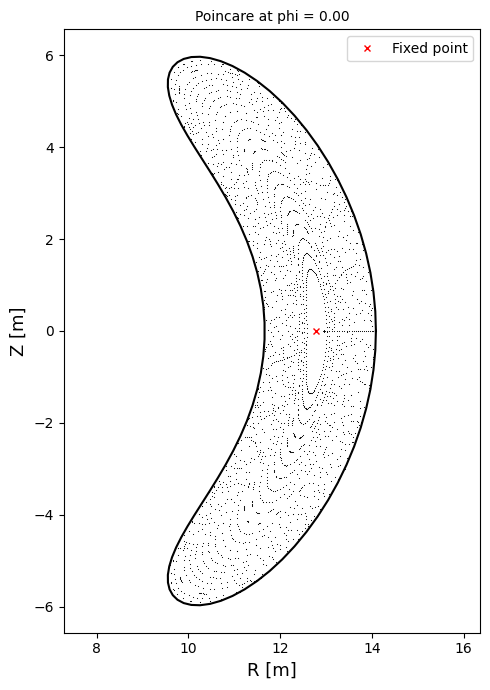

In [5]:
# QA vacuum fixed points example, based on the .toml input file

# converges but the axis is WRONG!

qa = SPECTRE.from_input_file('test_qa.toml')

xin = get_xinit_specwrap(qa)

force_real(xin, qa)


init_pts=[ np.array([[x, 0.] for x in np.linspace(-1,1, 25)]) for _ in range(7)]
qa.trace_fieldlines(init_pts, num_threads=7, num_phi_planes=1, num_transits=100) #run calculation

fig, ax = plt.subplots(figsize=(5, 7))
qa.tracer.plot(ax=plt.gca())
plot_infaces(xin, qa, ax=plt.gca())
# out.plot_poincare(ax=ax)

# Find the axis
r, z, s, t = qa.find_axis(guess=[-0.989, 6.1], nrestart=30, plot=True, ax=plt.gca())
print("Magnetic axis r z s t: ", r, z, s, t)

plt.legend()
plt.tight_layout()